In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

threshold = 0.85
csv_path = Path("labeling_speed_brainmri.csv")
if not csv_path.exists():
    csv_path = Path("bench") / csv_path
data = pd.read_csv(csv_path)
qualified = data.loc[data["dice"] >= threshold].copy()

print(f"Images meeting Dice >= {threshold:.2f}: {len(qualified)}")
print(qualified["mode"].value_counts().sort_index())

Images meeting Dice >= 0.85: 58
mode
manual        28
superpixel    30
Name: count, dtype: int64


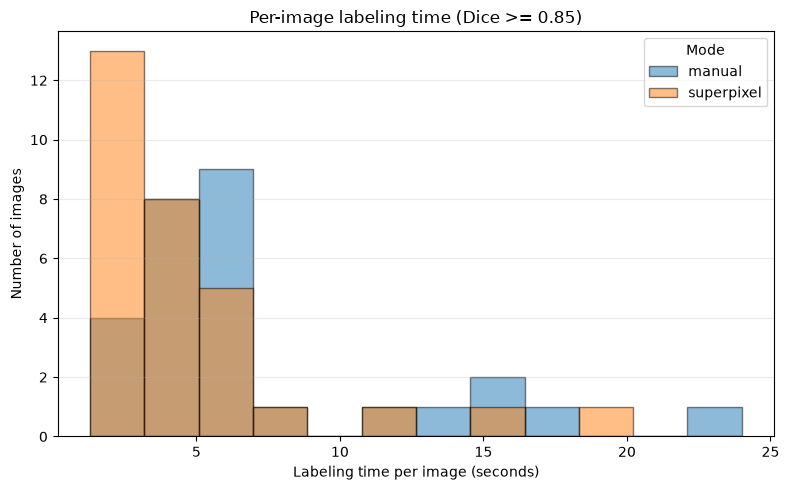

In [20]:
modes = sorted(qualified["mode"].unique())
bins = np.histogram_bin_edges(qualified["labeling_time_seconds"], bins=12)

fig, ax = plt.subplots(figsize=(8, 5))
for mode in modes:
    ax.hist(
        qualified.loc[qualified["mode"] == mode, "labeling_time_seconds"],
        bins=bins,
        alpha=0.5,
        label=mode,
        edgecolor="black",
    )
ax.set_title(f"Per-image labeling time (Dice >= {threshold:.2f})")
ax.set_xlabel("Labeling time per image (seconds)")
ax.set_ylabel("Number of images")
ax.legend(title="Mode")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

In [21]:
avg_dice = qualified.groupby("mode")["dice"].mean()
print(avg_dice)

avg_time = qualified.groupby("mode")["labeling_time_seconds"].mean()
print(avg_time)

mode
manual        0.887929
superpixel    0.890833
Name: dice, dtype: float64
mode
manual        7.228571
superpixel    4.833333
Name: labeling_time_seconds, dtype: float64
